In [1]:
!pip install contextily

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [contextily]


In [2]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from shapely.geometry import Polygon

from google.colab import drive
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

import numpy as np
from matplotlib import pyplot as plt


drive.mount('/content/drive')

# Importa e reprojeta os arquivos
AREAS_INTERESSE = gpd.read_file('/content/drive/MyDrive/PEmSE/area_interesse.shp').to_crs('EPSG:3857')
PASSAGENS_SAR = gpd.read_file('/content/drive/MyDrive/PEmSE/passagens_SAR.shp').to_crs('EPSG:3857')

# Calcula a área em km2 segundo a projeção definida
AREAS_INTERESSE['area_km2'] = AREAS_INTERESSE.to_crs('EPSG:3857').geometry.area / 1000000
PASSAGENS_SAR['area_km2'] = PASSAGENS_SAR.to_crs('EPSG:3857').geometry.area / 1000000

WEIGHTS = [1, 1.5, 0.5] # AC, NP e SO

VERBOSE_OUTPUT = True
VERBOSE_EVALUATION = True

print(f"Number of passages: {len(PASSAGENS_SAR)}")

print(AREAS_INTERESSE)

print(AREAS_INTERESSE.sum(numeric_only=True))

Mounted at /content/drive
Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [3]:
# indexes = np.array(PASSAGENS_SAR.index.tolist())
# # gerar máscara binária
# rng = np.random.default_rng()
# mascara_int = rng.integers(0, 2, size = len(PASSAGENS_SAR), dtype = int)
# mascara_int

def evaluate_passagens(mask_bin):
    selected_passagens = PASSAGENS_SAR.iloc[mask_bin.astype(bool)]
    # Penalidade alta se nenhuma passagem for selecionada
    if selected_passagens.empty:
        return 1e6

    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')
    # Se as passagens selecionadas não tocarem as áreas de interesse
    if intersecao.empty:
        return 1e6

    # Calcula área em km² para as faixas selecionadas
    area_intersections = intersecao.copy()
    area_intersections['area_km2'] = area_intersections.geometry.area / 1e6
    area_intersection_sum = area_intersections['area_km2'].sum(numeric_only=True)

    # Área dissolvida sem sobreposição
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1e6

    # Sobreposição normalizada (com proteção contra divisão por zero)
    over_areas = area_intersection_sum + area_uniao
    overlap = 0.0
    if over_areas > 0:
      overlap = (area_intersection_sum - area_uniao) / over_areas

    area_total = AREAS_INTERESSE['area_km2'].sum()
    area_covered = area_uniao / area_total
    passagens = len(selected_passagens) / len(PASSAGENS_SAR)

    w1, w2, w3 = WEIGHTS

    # Minimizar a área não coberta, a quantidade de passagens e a sobreposição
    score = (w1 * (1.0 - area_covered)) + (w2 * passagens) + (w3 * overlap)

    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )

    return score

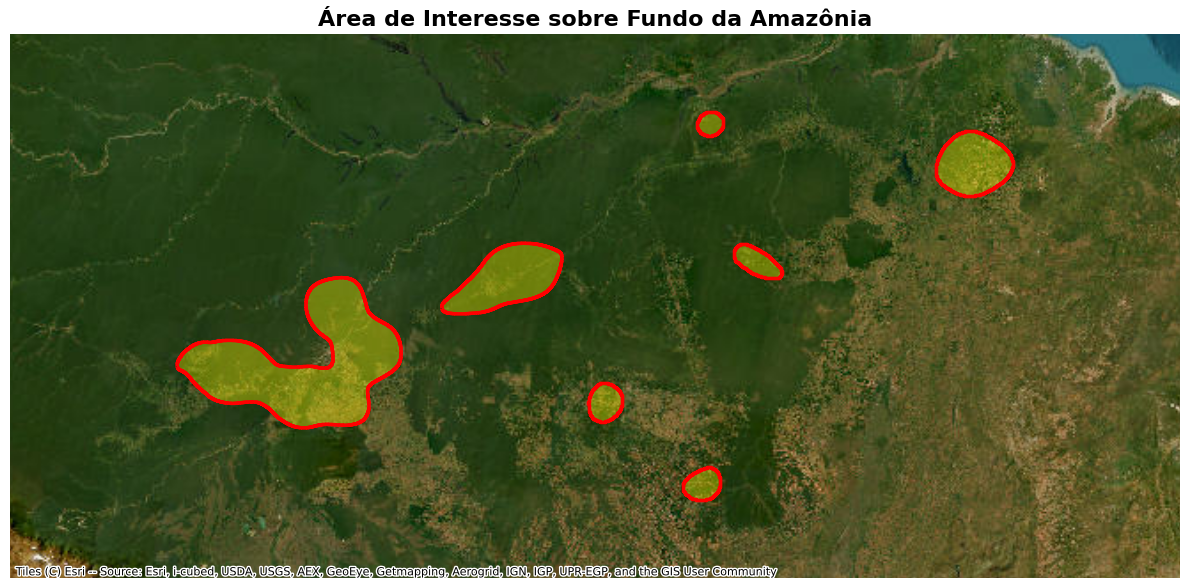

In [4]:
# Reprojetar para o sistema usado pelo mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:
def fitness_default(fob_value):
    """
    Função de aptidão para minimização.
    Garante que valores menores de fob tenham maior fitness na roleta.
    """
    if fob_value >= 0:
        return 1.0 / (1.0 + fob_value)
    return 1.0 + abs(fob_value)


class Individual:
    def __init__(self, x_bin, fob, fitness_func):
        self._fob = fob
        self._fitness = fitness_func
        self.x_bin = np.asarray(x_bin, dtype=int)

        # A própria fob avalia diretamente a máscara binária
        self.fob = float(fob(self.x_bin))
        self.fitness = float(fitness_func(self.fob))


class Population:
    def __init__(self, pop_size, crom_size, fob, fitness_func, p_init=0.5):
        self.pop_size = pop_size
        self.individuals = []
        rng = np.random.default_rng()
        for _ in range(pop_size):
            # Vetor binário de tamanho N correspondente às geometrias
            x_bin = (rng.random(size=crom_size) < p_init).astype(int)
            self.individuals.append(Individual(x_bin, fob, fitness_func))


class Roulette:
    def __init__(self, population):
        self.roulette_range = []
        total_fit = sum(ind.fitness for ind in population.individuals)

        # Prevenção contra divisão por zero
        if total_fit == 0:
            total_fit = 1e-9

        cumulative = 0.0
        for individual in population.individuals:
            cumulative += individual.fitness / total_fit
            self.roulette_range.append(cumulative)
        self.roulette_range[-1] = 1.0

    def spin(self):
        r = np.random.uniform(0, 1)
        for i, v in enumerate(self.roulette_range):
            if v > r:
                return i
        return len(self.roulette_range) - 1


def mutation(individual, pm):
    rng = np.random.default_rng()
    x_bin_mut = []
    for bit in individual.x_bin:
        prob = rng.random()
        if prob > pm:
            x_bin_mut.append(bit)
        else:
            x_bin_mut.append(bit ^ 1)
    return Individual(x_bin_mut, individual._fob, individual._fitness)

def cross(parent_1, parent_2):
    pc = int(len(parent_1.x_bin) / 2)
    child_1_bits = np.concatenate([parent_1.x_bin[:pc], parent_2.x_bin[pc:]])
    child_2_bits = np.concatenate([parent_2.x_bin[:pc], parent_1.x_bin[pc:]])

    child_1 = Individual(child_1_bits, parent_1._fob, parent_1._fitness)
    child_2 = Individual(child_2_bits, parent_1._fob, parent_1._fitness)
    return child_1, child_2

class GeoGeneticAlgorithm:
    def __init__(self):
        self.population = None
        self.best = None
        self.best_mask = None
        self.best_f_history = []
        self.fob = None

    def run(
        self,
        fob,
        n_geometries,
        pop_size=100,
        n_generations=50,
        pm=0.01,
        p_init=0.5,
        fitness_func=fitness_default,
        elitism=True,
        seed=None
    ):
        """
        Executa o Algoritmo Genético para seleção de geometrias.

        Parâmetros:
        - fob: função objetivo que recebe vetor binário/booleano 1D e retorna um float a minimizar.
        - n_geometries: len(gdf), quantidade de feições/bits do cromossomo.
        - pop_size: tamanho da população.
        - n_generations: número de iterações.
        - pm: probabilidade de mutação por gene/bit.
        - p_init: probabilidade inicial de uma geometria começar selecionada (1).
        - elitism: preserva a melhor solução encontrada para a geração seguinte.
        """
        if seed is not None:
            np.random.seed(seed)

        self.fob = fob
        self.best_f_history = []

        # Inicialização da população
        self.population = Population(pop_size, n_geometries, fob, fitness_func, p_init=p_init)

        for generation in range(n_generations):
            # Identifica o melhor indivíduo da geração (menor fob)
            current_best = min(self.population.individuals, key=lambda ind: ind.fob)
            self.best_f_history.append(current_best.fob)

            roulette = Roulette(self.population)
            new_individuals = []

            # Elitismo: mantém o melhor indivíduo
            if elitism:
                new_individuals.append(current_best)

            while len(new_individuals) < pop_size:
                idx1 = roulette.spin()
                idx2 = roulette.spin()

                parent_1 = self.population.individuals[idx1]
                parent_2 = self.population.individuals[idx2]

                child_1, child_2 = cross(parent_1, parent_2)

                child_1 = mutation(child_1, pm)
                child_2 = mutation(child_2, pm)

                new_individuals.append(child_1)
                if len(new_individuals) < pop_size:
                    new_individuals.append(child_2)

            if VERBOSE_OUTPUT:
                best = min(new_individuals, key=lambda ind: ind.fob)
                best_mask = best.x_bin.astype(bool)
                best_score = best.fob

                print(
                    "================>",
                    f"Geração {generation + 1}: ",
                    f"Melhor score obtido: {best_score:.4f} |",
                    f"Geometrias selecionadas: {best_mask.sum()}"
                )
            self.population.individuals = new_individuals

        # Melhor indivíduo final
        self.best = min(self.population.individuals, key=lambda ind: ind.fob)
        self.best_mask = self.best.x_bin.astype(bool)

        return self.best_mask, self.best.fob

    def plot_convergence(self):
        """Plota a curva de convergência do score."""
        if not self.best_f_history:
            raise ValueError("Execute o método 'run' antes de gerar o gráfico.")

        fig, ax = plt.subplots(figsize=(9, 4))

        # Gera o eixo X começando da geração 1 até N
        geracoes = range(1, len(self.best_f_history) + 1)
        ax.plot(geracoes, self.best_f_history, marker='o', markersize=3, color='tab:blue')

        # Força os ticks do eixo X a serem estritamente números inteiros
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

        ax.set_xlabel("Geração")
        ax.set_ylabel("Melhor Score f(x)")
        ax.set_title("Convergência do Algoritmo Genético")
        ax.grid(True, linestyle="--", alpha=0.6)

        plt.tight_layout()
        plt.show()

================> Geração 1:  Melhor score obtido: 1.0560 | Geometrias selecionadas: 327
================> Geração 2:  Melhor score obtido: 1.0560 | Geometrias selecionadas: 327
================> Geração 3:  Melhor score obtido: 1.0560 | Geometrias selecionadas: 327
================> Geração 4:  Melhor score obtido: 1.0477 | Geometrias selecionadas: 324
================> Geração 5:  Melhor score obtido: 1.0408 | Geometrias selecionadas: 319
================> Geração 6:  Melhor score obtido: 1.0408 | Geometrias selecionadas: 319
================> Geração 7:  Melhor score obtido: 1.0408 | Geometrias selecionadas: 319
================> Geração 8:  Melhor score obtido: 1.0358 | Geometrias selecionadas: 317
================> Geração 9:  Melhor score obtido: 1.0270 | Geometrias selecionadas: 310
================> Geração 10:  Melhor score obtido: 1.0259 | Geometrias selecionadas: 315
================> Geração 11:  Melhor score obtido: 1.0240 | Geometrias selecionadas: 308
================> G

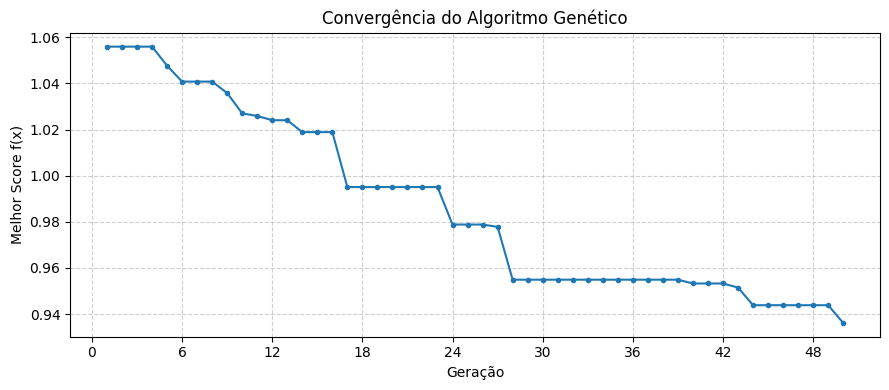

In [8]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = True

ga = GeoGeneticAlgorithm()
best_mask, best_score = ga.run(
    fob           = evaluate_passagens,
    n_geometries  = len(PASSAGENS_SAR),
    pop_size      = 30,
    n_generations = 50,
    pm            = 0.02,
    p_init        = 0.5,
    elitism       = True,
    seed          = 46
)

print(f"\nMelhor score obtido: {best_score:.4f}")
print(f"Geometrias selecionadas: {best_mask.sum()}")

# Filtrando o GeoDataFrame original com a melhor máscara encontrada
gdf_otimizado = PASSAGENS_SAR.iloc[best_mask]

# Plot da convergência
ga.plot_convergence()

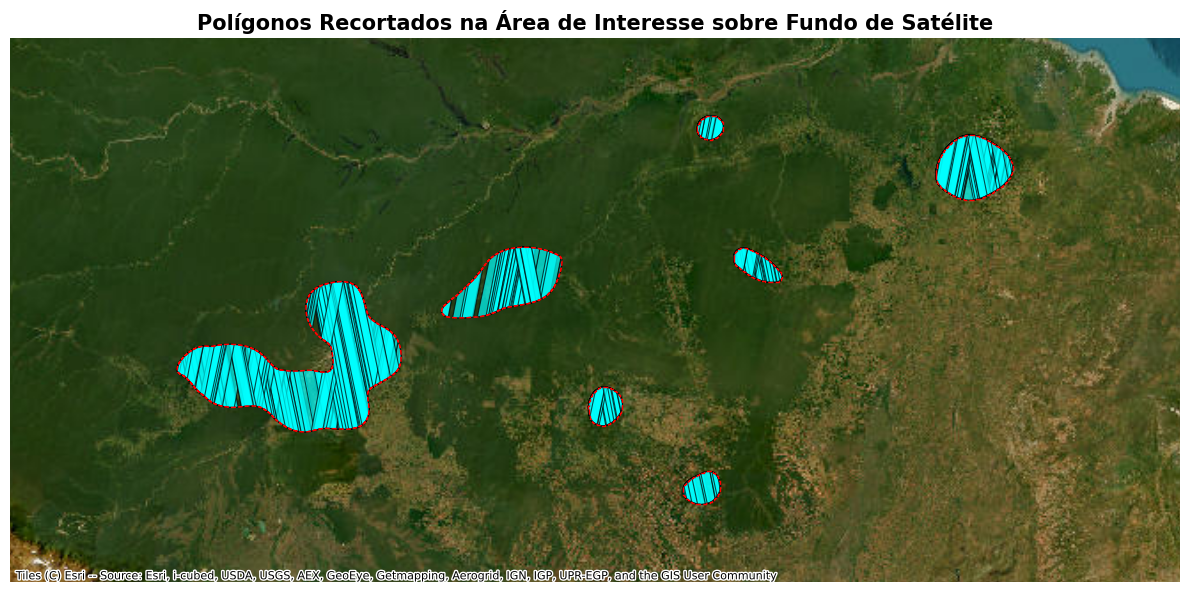

In [9]:
# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = gdf_otimizado.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
VERBOSE_EVALUATION = True
VERBOSE_OUTPUT = True

evaluate_passagens(best_mask)

Área coberta (AC): 0.982562 | Número de passagens (NP): 275 | Sobreposição (SO): 0.662191 | Score (Loss): 0.936141


np.float64(0.9361405394317828)

In [11]:
def extrair_metricas_tabela(best_mask):
    # 1. Filtra as passagens selecionadas pelo indivíduo
    selected_passagens = PASSAGENS_SAR.iloc[best_mask.astype(bool)].copy()

    if selected_passagens.empty:
        return {"area_nao_coberta_pct": 100.0, "passagens_com_sobreposicao": 0}

    # 2. Interseção com as Áreas de Interesse
    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')

    # 3. Cálculo da Área Não Coberta (%)
    uniao = intersecao.geometry.union_all()
    area_uniao_km2 = uniao.area / 1e6
    area_total_km2 = AREAS_INTERESSE['area_km2'].sum()

    area_covered = area_uniao_km2 / area_total_km2
    area_nao_coberta_pct = (1.0 - area_covered) * 100.0

    # 4. Cálculo de "Passagens com sobreposição"
    # Faz um auto-join espacial entre as passagens selecionadas para detectar interseções
    sjoin_overlaps = gpd.sjoin(
        selected_passagens,
        selected_passagens,
        how='inner',
        predicate='intersects'
    )

    # Descarta a auto-interseção (linha com ela mesma)
    sjoin_overlaps = sjoin_overlaps[sjoin_overlaps.index != sjoin_overlaps.index_right]

    # Contagem de passagens únicas que se sobrepõem a pelo menos uma outra
    passagens_com_sobreposicao = sjoin_overlaps.index.nunique()

    print(f"Passagens com sobreposição: {passagens_com_sobreposicao}")
    print(f"Área não coberta: {area_nao_coberta_pct:.2f}%")

    return {
        "passagens_com_sobreposicao": passagens_com_sobreposicao,
        "area_nao_coberta_pct": area_nao_coberta_pct
    }

# Exemplo de chamada:
metricas = extrair_metricas_tabela(best_mask)

Passagens com sobreposição: 275
Área não coberta: 1.74%
